<a href="https://colab.research.google.com/github/mfaridzmaulana/KLASIFIKASI-CITRA-DENGAN-CNN/blob/main/notebooks/04_hog_svm_MFM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:

import os
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import hog
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Lokasi dataset
DATASET_DIR = "/content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN/DATA MENTAH"

OUTPUT_DIR = os.path.dirname(DATASET_DIR)

# Membaca hasil pembagian dataset
FILE_SPLIT = os.path.join(OUTPUT_DIR, "dataset_split.npz")

data = np.load(FILE_SPLIT)

X_train = data["X_train"]
X_val = data["X_val"]
X_test = data["X_test"]

y_train = data["y_train"]
y_val = data["y_val"]
y_test = data["y_test"]

k_train = data["k_train"]
k_val = data["k_val"]
k_test = data["k_test"]

nama_kelas = ["TAS", "BUKU GAMBAR", "LAPTOP"]

print("Persiapan HOG + SVM berhasil!")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))


Persiapan HOG + SVM berhasil!
Training: 84
Validation: 18
Testing: 18


In [7]:

def ekstraksi_hog(dataset):

    fitur = []

    for gambar in dataset:

        hasil = hog(
            gambar,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            channel_axis=-1
        )

        fitur.append(hasil)

    return np.array(fitur)

print("Memulai ekstraksi fitur HOG...")

X_train_hog = ekstraksi_hog(X_train)
X_val_hog = ekstraksi_hog(X_val)
X_test_hog = ekstraksi_hog(X_test)

print("Ekstraksi HOG selesai!")
print("Training HOG:", X_train_hog.shape)
print("Validation HOG:", X_val_hog.shape)
print("Testing HOG:", X_test_hog.shape)


Memulai ekstraksi fitur HOG...
Ekstraksi HOG selesai!
Training HOG: (84, 8100)
Validation HOG: (18, 8100)
Testing HOG: (18, 8100)


In [8]:

model_svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    )
)

print("Memulai training HOG + SVM...")

model_svm.fit(X_train_hog, y_train)

print("Training HOG + SVM berhasil!")


Memulai training HOG + SVM...
Training HOG + SVM berhasil!


In [9]:

# Evaluasi validation
pred_val = model_svm.predict(X_val_hog)

akurasi_val = accuracy_score(y_val, pred_val)

print("HASIL VALIDATION HOG + SVM")
print("Akurasi:", round(akurasi_val * 100, 2), "%")

# Evaluasi testing
pred_test = model_svm.predict(X_test_hog)

akurasi_test = accuracy_score(y_test, pred_test)

print("\nHASIL TESTING HOG + SVM")
print("Akurasi:", round(akurasi_test * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    pred_test,
    labels=[0, 1, 2],
    target_names=nama_kelas,
    zero_division=0
))


HASIL VALIDATION HOG + SVM
Akurasi: 61.11 %

HASIL TESTING HOG + SVM
Akurasi: 72.22 %

Classification Report:
              precision    recall  f1-score   support

         TAS       0.80      0.67      0.73         6
 BUKU GAMBAR       0.60      1.00      0.75         6
      LAPTOP       1.00      0.50      0.67         6

    accuracy                           0.72        18
   macro avg       0.80      0.72      0.71        18
weighted avg       0.80      0.72      0.71        18



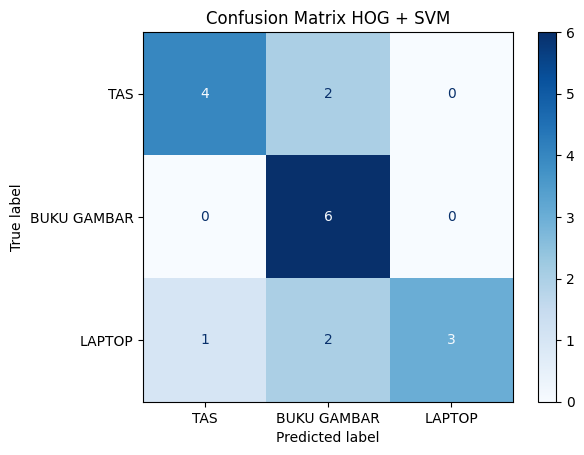

In [10]:

cm = confusion_matrix(
    y_test,
    pred_test,
    labels=[0, 1, 2]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nama_kelas
)

display.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix HOG + SVM")
plt.show()


In [11]:

print("EVALUASI BERDASARKAN KONDISI")
print("=" * 40)

for kondisi in ["KONDISI IDEAL", "KONDISI SULIT"]:

    indeks = np.where(k_test == kondisi)[0]

    akurasi = accuracy_score(
        y_test[indeks],
        pred_test[indeks]
    )

    print(kondisi)
    print("Jumlah gambar:", len(indeks))
    print("Akurasi:", round(akurasi * 100, 2), "%")
    print("-" * 40)


EVALUASI BERDASARKAN KONDISI
KONDISI IDEAL
Jumlah gambar: 9
Akurasi: 77.78 %
----------------------------------------
KONDISI SULIT
Jumlah gambar: 9
Akurasi: 66.67 %
----------------------------------------


In [12]:

import joblib

MODEL_FILE = os.path.join(
    OUTPUT_DIR,
    "model_hog_svm.pkl"
)

joblib.dump(model_svm, MODEL_FILE)

print("Model HOG + SVM berhasil disimpan!")
print(MODEL_FILE)


Model HOG + SVM berhasil disimpan!
/content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN/model_hog_svm.pkl
